# Imports

In [1]:
import os
os.environ['KERAS_BACKEND'] = 'tensorflow'

import keras
import numpy as np
import sklearn.metrics
from tqdm import tqdm as tqdm
import sklearn.model_selection
import matplotlib.pyplot as plt
import tokenmonster
import pandas as pd
import datasets
import math
from sklearn.metrics import roc_curve, auc
import seaborn as sns

import sentencepiece as spm

# tokenmonster.set_local_directory("../tokenmonster_cache")

I0000 00:00:1795761400.204340  206302 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


# Tokenizer

Train your own tokenizer on an English corpus or load a pretrained tokenizer for English sentences (see the one used in class)

In [2]:
train_ds = datasets.load_dataset('stanfordnlp/imdb', split='train', cache_dir='dataset')
test_ds = datasets.load_dataset('stanfordnlp/imdb', split='test', cache_dir='dataset')

In [4]:
# with open("tokenizer_corpus.txt", "w", encoding="utf-8") as f:
#     for s1, s2 in tqdm(zip(train_ds['text'], test_ds['text'])):
#         f.write(s1 + '\n')
#         f.write(s2 + '\n')

In [3]:
tokenizers_folder = 'tokenizers/'

# for i in [4, 8, 16, 24, 32, 48]:
#     spm.SentencePieceTrainer.train(
#         input='tokenizer_corpus.txt',
#         model_prefix=tokenizers_folder + f'tokenizer{i}k',

#         model_type='unigram',
#         vocab_size=i * 1000,

#         character_coverage=1.0,
#         byte_fallback=True,

#         pad_id=0,
#         unk_id=1,
#         bos_id=2,
#         eos_id=3,
#     )

In [4]:
tokenizer4k = spm.SentencePieceProcessor(
    model_file=tokenizers_folder + 'tokenizer4k.model'
)
tokenizer8k = spm.SentencePieceProcessor(
    model_file=tokenizers_folder + 'tokenizer8k.model'
)
tokenizer16k = spm.SentencePieceProcessor(
    model_file=tokenizers_folder + 'tokenizer16k.model'
)
tokenizer24k = spm.SentencePieceProcessor(
    model_file=tokenizers_folder + 'tokenizer24k.model'
)
tokenizer32k = spm.SentencePieceProcessor(
    model_file=tokenizers_folder + 'tokenizer32k.model'
)
tokenizer48k = spm.SentencePieceProcessor(
    model_file=tokenizers_folder + 'tokenizer48k.model'
)

text = 'tokenizer, how are you?'

tokens = tokenizer16k.encode(text, out_type=str)
ids = tokenizer16k.encode(text, out_type=int)

print(tokens)
print(ids)

print(tokenizer16k.decode(ids))

['▁to', 'ken', 'izer', ',', '▁how', '▁are', '▁you', '?']
[267, 5899, 9529, 261, 381, 293, 290, 334]
tokenizer, how are you?


# Dataset

Load the dataset (we will be using [imdb](https://huggingface.co/datasets/stanfordnlp/imdb)). Pretokenize data or make a loader that tokenizes the sentenses as you iterate through the dataset.

In [5]:
train_X = list(train_ds['text'])
train_y = np.array(train_ds['label'], dtype='float32')
test_X = list(test_ds['text'])
test_y = np.array(test_ds['label'], dtype='float32')

In [8]:
print(f'''Распределение на положительные и отрицательные классы:
            positive:      negative:
train:      {np.sum(train_y == 1)}          {np.sum(train_y == 0)}      
val:        {np.sum(test_y == 1)}           {np.sum(test_y == 0)}
''')

Распределение на положительные и отрицательные классы:
            positive:      negative:
train:      12500          12500      
val:        12500           12500



In [71]:
train_tok_4k = tokenizer4k.encode(train_X, out_type=int)
test_tok_4k = tokenizer4k.encode(test_X, out_type=int)

train_tok_8k = tokenizer8k.encode(train_X, out_type=int)
test_tok_8k = tokenizer8k.encode(test_X, out_type=int)

train_tok_16k = tokenizer16k.encode(train_X, out_type=int)
test_tok_16k = tokenizer16k.encode(test_X, out_type=int)

train_tok_24k = tokenizer24k.encode(train_X, out_type=int)
test_tok_24k = tokenizer24k.encode(test_X, out_type=int)

train_tok_32k = tokenizer32k.encode(train_X, out_type=int)
test_tok_32k = tokenizer32k.encode(test_X, out_type=int)

train_tok_48k = tokenizer48k.encode(train_X, out_type=int)
test_tok_48k = tokenizer48k.encode(test_X, out_type=int)

In [72]:
train_lens = np.array(list(map(len, train_X)))
test_lens = np.array(list(map(len, test_X)))

train_tok_4k_lens = np.array(list(map(len, train_tok_4k)))
test_tok_4k_lens = np.array(list(map(len, test_tok_4k)))

train_tok_8k_lens = np.array(list(map(len, train_tok_8k)))
test_tok_8k_lens = np.array(list(map(len, test_tok_8k)))

train_tok_16k_lens = np.array(list(map(len, train_tok_16k)))
test_tok_16k_lens = np.array(list(map(len, test_tok_16k)))

train_tok_24k_lens = np.array(list(map(len, train_tok_24k)))
test_tok_24k_lens = np.array(list(map(len, test_tok_24k)))

train_tok_32k_lens = np.array(list(map(len, train_tok_32k)))
test_tok_32k_lens = np.array(list(map(len, test_tok_32k)))

train_tok_48k_lens = np.array(list(map(len, train_tok_48k)))
test_tok_48k_lens = np.array(list(map(len, test_tok_48k)))

In [74]:
f = np.mean
print(f'''
            train:              Test:
Symbols:          {f(train_lens):.4f}    \t     {f(test_lens):.4f}
Tok_4k:           {f(train_tok_4k_lens):.4f}     \t     {f(test_tok_4k_lens):.4f}
Tok_8k:           {f(train_tok_8k_lens):.4f}    \t     {f(test_tok_8k_lens):.4f}
Tok_16k:          {f(train_tok_16k_lens):.4f}    \t     {f(test_tok_16k_lens):.4f}
Tok_24k:          {f(train_tok_24k_lens):.4f}    \t     {f(test_tok_24k_lens):.4f}
Tok_32k:          {f(train_tok_32k_lens):.4f}    \t     {f(test_tok_32k_lens):.4f}
Tok_48k:          {f(train_tok_48k_lens):.4f}    \t     {f(test_tok_48k_lens):.4f}
''')


            train:              Test:
Symbols:          1325.0696    	     1293.7924
Tok_4k:           368.6455     	     359.9698
Tok_8k:           334.4530    	     326.7860
Tok_16k:          311.7036    	     304.6459
Tok_24k:          302.6683    	     295.8305
Tok_32k:          297.7450    	     291.0350
Tok_48k:          292.8720    	     286.2723



In [6]:
class DefaultBatchDataset(keras.utils.PyDataset):
    def __init__(self, X, y, max_len=500, batch_size=64, q=0.5, seed=1, pad_token_id=0, shuffle=False, **kwargs):
        super().__init__(**kwargs)
        self.X = X
        self.y = np.array(y)
        self.batch_size = batch_size
        self.q = q
        self.max_len = max_len
        self.rng = np.random.default_rng(seed=seed)
        self.shuffle = shuffle
        self.pad_token_id = pad_token_id

        self.X_lens = np.array(list(map(len, self.X)), dtype='int32')

        self.idxs = np.arange(len(self.X))

    def __len__(self):
        return -(-len(self.X) // self.batch_size)

    def __getitem__(self, idx):
        ind = self.idxs[idx * self.batch_size: (idx + 1) * self.batch_size]

        q = math.ceil(np.quantile(self.X_lens[ind], self.q))
        l = min(self.max_len, q)

        return keras.utils.pad_sequences(
            [self.X[i] for i in ind],
            maxlen=l,
            padding='post',
            truncating='post',
            value=self.pad_token_id
        ), self.y[ind].reshape(-1, 1)

    def on_epoch_end(self):
        if self.shuffle:
            self.rng.shuffle(self.idxs)

# Model

Implement your model. The model should have the Transformer architecture. Remember to mask out padding tokens.

In [7]:
@keras.saving.register_keras_serializable()
class EmbeddingAndPositionalEncoding(keras.layers.Layer):
    def __init__(self, vocab_size: int, embed_size: int, max_len: int, **kwargs):
        super().__init__(**kwargs)
        self.vocab_size = vocab_size
        self.embed_size = embed_size
        self.max_len = max_len

        self.embedding_layer = keras.layers.Embedding(vocab_size, embed_size)
        self.positional_embedding_layer = keras.layers.Embedding(max_len, embed_size)

    def call(self, x):
        pos = keras.ops.arange(0, keras.ops.shape(x)[1], 1)

        x_emb = self.embedding_layer(x)
        pos_emb = self.positional_embedding_layer(pos)

        return x_emb + pos_emb

    def compute_output_shape(self, input_shape):
        return (input_shape[0], input_shape[1], self.embed_size)

In [8]:
@keras.saving.register_keras_serializable()
class SwiGLU(keras.layers.Layer):
    def __init__(self, embed_size: int, ff_dim: int, **kwargs):
        super().__init__(**kwargs)

        self.gate_proj = keras.layers.Dense(ff_dim, use_bias=False)
        self.up_proj = keras.layers.Dense(ff_dim, use_bias=False)
        self.down_proj = keras.layers.Dense(embed_size, use_bias=False)

    def call(self, x):
        gate = keras.activations.swish(self.gate_proj(x))
        up = self.up_proj(x)
        return self.down_proj(gate * up)


In [9]:
@keras.saving.register_keras_serializable()
class TransformerBlock(keras.layers.Layer):
    def __init__(self, embed_size, num_heads, ff_dim, dropout, **kwargs):
        super().__init__(**kwargs)
        self.embed_size = embed_size
        self.num_heads = num_heads
        self.ff_dim = ff_dim
        self.dropout = dropout

        self.layer_norm1 = keras.layers.LayerNormalization()
        self.Mha = keras.layers.MultiHeadAttention(num_heads, embed_size // num_heads, dropout=dropout)
        self.dropout1 = keras.layers.Dropout(dropout)

        self.layer_norm2 = keras.layers.LayerNormalization()
        self.swiglu = SwiGLU(embed_size, ff_dim)
        self.dropout2 = keras.layers.Dropout(dropout)

    def _forward(self, x, value_mask=None, training=False, get_attention=False):
        x_mha = self.layer_norm1(x)

        if not get_attention:
            x_mha = self.Mha(x_mha, x_mha, value_mask=value_mask, training=training)
        else:
            x_mha, scores = self.Mha(x_mha, x_mha, value_mask=value_mask, training=training, return_attention_scores=True)

        x_mha = self.dropout1(x_mha, training=training)
        x = x + x_mha

        x_ff = self.layer_norm2(x)
        x_ff = self.swiglu(x_ff)
        x_ff = self.dropout2(x_ff, training=training)

        if not get_attention:
            return x + x_ff
        else:
            return x + x_ff, scores


    def call(self, x, value_mask=None, training=False):
        return self._forward(x, value_mask, training)

    def get_attention(self, x, value_mask=None):
        return self._forward(x, value_mask, False, True)

    def compute_output_shape(self, input_shape):
        return input_shape

In [10]:
@keras.saving.register_keras_serializable()
class Transformer(keras.Model):
    def __init__(self, vocab_size: int, embed_size: int, max_len: int, num_blocks: int, num_heads: int, ff_dim: int, dropout: float, pad_token_id: int, name: str, **kwargs):
        super().__init__(name=name, **kwargs)

        self.vocab_size = vocab_size
        self.embed_size = embed_size
        self.max_len = max_len
        self.num_blocks = num_blocks
        self.num_heads = num_heads
        self.ff_dim = ff_dim
        self.dropout = dropout
        self.pad_token_id = pad_token_id
        self.name = name

        self.emb_and_pos_enc_layer = EmbeddingAndPositionalEncoding(vocab_size, embed_size, max_len, name='emb_and_pos_enc')

        self.transformer_blocks = [TransformerBlock(embed_size, num_heads, ff_dim, dropout, name=f'MHA_{i}') for i in range(num_blocks)]
        self.classifier = keras.layers.Dense(1, name='classifier')

    def build(self, input_shape):
        self.cls_token = self.add_weight(
            shape=(1, 1, self.embed_size),
            initializer='random_normal',
            name='cls_token'
        )

        super().build(input_shape)

    def _forward(self, x, training=False, get_attention=False):
        value_mask = keras.ops.concatenate([
            keras.ops.ones((keras.ops.shape(x)[0], 1), dtype='bool'),
            keras.ops.cast(
                keras.ops.not_equal(x, self.pad_token_id),
                dtype='bool'
            )
        ], axis=1)

        x_emb = self.emb_and_pos_enc_layer(x)
        cls_tok = keras.ops.broadcast_to(self.cls_token, (keras.ops.shape(x)[0], 1, self.embed_size))
        x_cls_and_emb = keras.ops.concatenate([cls_tok, x_emb], axis=1)
        x = x_cls_and_emb

        scores = []
        for trans_bl in self.transformer_blocks:
            if not get_attention:
                x = trans_bl(x, value_mask=value_mask, training=training)
            else:
                x, score = trans_bl.get_attention(x, value_mask=value_mask)
                scores.append(score)

        res = x[:, 0, :]
        res = self.classifier(res)

        if not get_attention:
            return res
        else:
            return res, scores

    def call(self, x, training=False):
        return self._forward(x, training)

    def get_attention(self, x):
        return self._forward(x, False, True)

    def get_config(self):
        config = super().get_config()
        config.update({
            'vocab_size': self.vocab_size,
            'embed_size': self.embed_size,
            'max_len': self.max_len,
            'num_blocks': self.num_blocks,
            'num_heads': self.num_heads,
            'ff_dim': self.ff_dim,
            'dropout': self.dropout,
            'pad_token_id': self.pad_token_id,
        })
        return config


# Training

Train the model. Choose model size, batch size, loss, learning rate schedule.

In [11]:
MAX_LEN = 500
BATCH_SIZE = 32
EPOCHS = 20

model = Transformer(
    vocab_size=tokenizer16k.vocab_size(), 
    embed_size=128,
    max_len=MAX_LEN, 
    num_blocks=6,
    num_heads=8, 
    ff_dim=512,
    dropout=0.1,
    pad_token_id=tokenizer16k.pad_id(),
    name='Transformer_model'
)

inputs = keras.layers.Input(shape=(None,), name='Input_layer')
outputs = model(inputs, training=True)
model = keras.Model(inputs=inputs, outputs=outputs)
model.summary(expand_nested=True)

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Input_layer (InputLayer)        │ (None, None)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Transformer_model (Transformer) │ (None, 1)              │     3,691,265 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ emb_and_pos_enc            │ (None, None, 128)      │     2,112,000 │
│ (EmbeddingAndPositionalEncodin… │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ MHA_0 (TransformerBlock)   │ (None, None, 128)      │       263,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ MHA_1 (TransformerBlock)   │ (None, None, 128)      │       263,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ MHA_2 (TransformerBlock)   │ (None, None, 128)      │       263,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ MHA_3 (TransformerBlock)   │ (None, None, 128)      │       263,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ MHA_4 (TransformerBlock)   │ (None, None, 128)      │       263,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ MHA_5 (TransformerBlock)   │ (None, None, 128)      │       263,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ classifier (Dense)         │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 3,691,265 (14.08 MB)

 Trainable params: 3,691,265 (14.08 MB)

 Non-trainable params: 0 (0.00 B)

In [23]:
train_tok_X = tokenizer16k.encode(train_X)
test_tok_X = tokenizer16k.encode(test_X)

train_dataset = DefaultBatchDataset(train_tok_X, train_y, max_len=MAX_LEN, batch_size=BATCH_SIZE, q=0.8, shuffle=True, pad_token_id=tokenizer16k.pad_id())
test_dataset = DefaultBatchDataset(test_tok_X, test_y, max_len=MAX_LEN, batch_size=BATCH_SIZE, q=0.8, shuffle=False, pad_token_id=tokenizer16k.pad_id())

batch_num = len(train_dataset)

In [24]:
STEPS_PER_EPOCH = len(train_dataset)
TOTAL_STEPS = STEPS_PER_EPOCH * EPOCHS

WARMUP_RATIO = 0.1
WARMUP_STEPS = int(TOTAL_STEPS * WARMUP_RATIO)

cosine_decay = keras.optimizers.schedules.CosineDecay(
    initial_learning_rate=0.0,
    warmup_target=1e-3,
    warmup_steps=WARMUP_STEPS,
    decay_steps=TOTAL_STEPS - WARMUP_STEPS,
    alpha=0.1
)

model.compile(
    loss=keras.losses.BinaryCrossentropy(from_logits=True),
    optimizer=keras.optimizers.AdamW(learning_rate=cosine_decay),
    metrics=[
        'accuracy',
        keras.metrics.AUC(name='AUC', from_logits=True) 
    ]
) 

In [25]:
SAVE_DIR = ''

def make_callbacks(name):
    return [
        keras.callbacks.ModelCheckpoint(
            filepath=os.path.join(SAVE_DIR, f'{name}.keras'),
            monitor='val_AUC',
            mode='max',
            save_best_only=True,
            save_weights_only=False,
            verbose=1
        ),

        keras.callbacks.EarlyStopping(
            monitor='val_AUC',
            patience=4,
            mode='max',
            restore_best_weights=True,
            verbose=1
        )
    ]

In [26]:
model.fit(train_dataset, validation_data=test_dataset, epochs=EPOCHS, callbacks=make_callbacks('model'))

Epoch 1/20


KeyboardInterrupt: 

In [12]:
model_load_1 = keras.models.load_model('model_40_600_2_2_160.keras')
model_load_2 = keras.models.load_model('model_99_600_2_3_396.keras')
model_load_3 = keras.models.load_model('model_128_500_3_4_512.keras')
model_load_4 = keras.models.load_model('model_128_600_6_8_512.keras')

In [164]:
model_load_1.summary(expand_nested=True)

Model: "functional_13"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Input_layer (InputLayer)        │ (None, None)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Transformer_model (Transformer) │ (None, 1)              │       715,921 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ emb_and_pos_enc            │ (None, None, 40)       │       664,000 │
│ (EmbeddingAndPositionalEncodin… │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ MHA_0 (TransformerBlock)   │ (None, None, 40)       │        25,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ MHA_1 (TransformerBlock)   │ (None, None, 40)       │        25,920 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ classifier (Dense)         │ (None, 1)              │            41 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,147,764 (8.19 MB)

 Trainable params: 715,921 (2.73 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 1,431,843 (5.46 MB)

In [165]:
model_load_2.summary(expand_nested=True)

Model: "functional_12"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Input_layer (InputLayer)        │ (None, None)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Transformer_model (Transformer) │ (None, 1)              │     1,958,815 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ emb_and_pos_enc            │ (None, None, 99)       │     1,643,400 │
│ (EmbeddingAndPositionalEncodin… │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ MHA_0 (TransformerBlock)   │ (None, None, 99)       │       157,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ MHA_1 (TransformerBlock)   │ (None, None, 99)       │       157,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ classifier (Dense)         │ (None, 1)              │           100 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 5,876,446 (22.42 MB)

 Trainable params: 1,958,815 (7.47 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 3,917,631 (14.94 MB)

In [166]:
model_load_3.summary(expand_nested=True)

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Input_layer (InputLayer)        │ (None, None)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Transformer_model (Transformer) │ (None, 1)              │     2,901,761 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ emb_and_pos_enc            │ (None, None, 128)      │     2,112,000 │
│ (EmbeddingAndPositionalEncodin… │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ MHA_0 (TransformerBlock)   │ (None, None, 128)      │       263,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ MHA_1 (TransformerBlock)   │ (None, None, 128)      │       263,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ MHA_2 (TransformerBlock)   │ (None, None, 128)      │       263,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ classifier (Dense)         │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8,705,284 (33.21 MB)

 Trainable params: 2,901,761 (11.07 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 5,803,523 (22.14 MB)

In [167]:
model_load_4.summary(expand_nested=True)

Model: "functional_11"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ Input_layer (InputLayer)        │ (None, None)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ Transformer_model (Transformer) │ (None, 1)              │     3,704,065 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ emb_and_pos_enc            │ (None, None, 128)      │     2,124,800 │
│ (EmbeddingAndPositionalEncodin… │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ MHA_0 (TransformerBlock)   │ (None, None, 128)      │       263,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ MHA_1 (TransformerBlock)   │ (None, None, 128)      │       263,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ MHA_2 (TransformerBlock)   │ (None, None, 128)      │       263,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ MHA_3 (TransformerBlock)   │ (None, None, 128)      │       263,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ MHA_4 (TransformerBlock)   │ (None, None, 128)      │       263,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ MHA_5 (TransformerBlock)   │ (None, None, 128)      │       263,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│    └ classifier (Dense)         │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,112,196 (42.39 MB)

 Trainable params: 3,704,065 (14.13 MB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 7,408,131 (28.26 MB)

# Evaluation

Evaluate the model you trained on the test dataset. Plot the ROC curve.

In [27]:
test_dataset_500 = DefaultBatchDataset(test_tok_X, test_y, max_len=500, batch_size=32, q=0.8, shuffle=False, pad_token_id=tokenizer16k.pad_id())
test_dataset_600 = DefaultBatchDataset(test_tok_X, test_y, max_len=600, batch_size=32, q=0.8, shuffle=False, pad_token_id=tokenizer16k.pad_id())

In [28]:
y_pred_1 = model_load_1.predict(test_dataset_600)

782/782 ━━━━━━━━━━━━━━━━━━━━ 201s 257ms/step


In [ ]:
y_pred_2 = model_load_2.predict(test_dataset_600)

 34/782 ━━━━━━━━━━━━━━━━━━━━ 5:44 461ms/step

In [ ]:
y_pred_3 = model_load_3.predict(test_dataset_500)

782/782 ━━━━━━━━━━━━━━━━━━━━ 720s 921ms/step


In [ ]:
y_pred_4 = model_load_4.predict(test_dataset_600)

782/782 ━━━━━━━━━━━━━━━━━━━━ 2260s 3s/step


In [ ]:
y_pred_1 = 1 / (1 + np.exp(-y_pred_1.reshape(-1)))
y_pred_2 = 1 / (1 + np.exp(-y_pred_2.reshape(-1)))
y_pred_3 = 1 / (1 + np.exp(-y_pred_3.reshape(-1)))
y_pred_4 = 1 / (1 + np.exp(-y_pred_4.reshape(-1)))

Text(0.5, 1.0, 'model_1 ROC curve (AUC = 0.9235)')

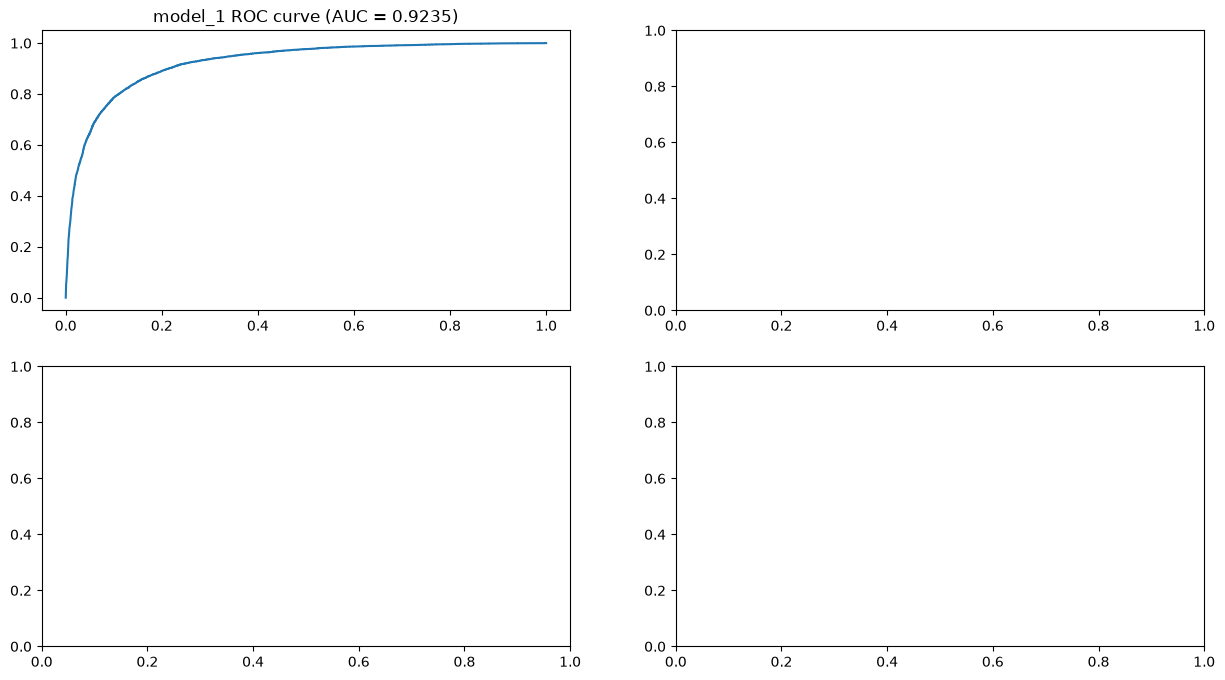

In [ ]:
fig, ax = plt.subplots(2, 2, figsize=(15, 8))
fpr, tpr, _ = roc_curve(test_y, y_pred_1)
roc_auc = auc(fpr, tpr)
ax[0, 0].plot(fpr, tpr)
ax[0, 0].set_title(f'model_1 ROC curve (AUC = {roc_auc:.4f})')

fpr, tpr, _ = roc_curve(test_y, y_pred_2)
roc_auc = auc(fpr, tpr)
ax[0, 1].plot(fpr, tpr)
ax[0, 1].set_title(f'model_2 all ROC curve (AUC = {roc_auc:.4f})')

fpr, tpr, _ = roc_curve(test_y, y_pred_3)
roc_auc = auc(fpr, tpr)
ax[1, 0].plot(fpr, tpr)
ax[1, 0].set_title(f'model_3 ROC curve (AUC = {roc_auc:.4f})')

fpr, tpr, _ = roc_curve(test_y, y_pred_4)
roc_auc = auc(fpr, tpr)
ax[1, 1].plot(fpr, tpr)
ax[1, 1].set_title(f'model_4 ROC curve (AUC = {roc_auc:.4f})')

Inspect the best model performance closer. Come up with some sentences (in English). Does the model output sensible results?

In [133]:
def label_text(text: str, model: keras.Model, threshold: float = 0.5, max_length: int | None = None):
    '''Computes the model output for `text` and outputs the predicted label

    Arguments:
        text: text to label
        model: model to use
        threshold: threshold to use
        max_length: max length for tokenization
    
    Return:
        Predicted label'''
    tokenized = np.array(tokenizer16k.tokenize(text)[:max_length])
    if max_length is not None:
        tokenized = tokenized[:max_length]
        
    y = model(tokenized.reshape(1, -1))
    res = 1 / (1 + np.exp(-y))
    return 'positive' if res > threshold else 'negative', res


In [134]:
positive_reviews = [
    "This movie was absolutely fantastic! The acting was outstanding, the story was engaging, and the cinematography was beautiful. I enjoyed every minute of it.",
    "One of the best films I have watched in years. The characters felt realistic, the dialogue was brilliant, and the ending was both emotional and satisfying.",
    "A truly wonderful experience. The director managed to create an atmosphere that kept me interested from beginning to end. Highly recommended!",
    "I did not expect much from this movie, but it completely surprised me. Excellent performances, great music, and a beautifully written story.",
    "The film has some minor flaws, but its strong performances, excellent pacing, and emotional depth make it a very enjoyable experience."
]

negative_reviews = [
    "This movie was absolutely terrible. The acting was wooden, the dialogue was boring, and the plot made no sense. I regret wasting my time watching it.",
    "One of the worst films I have ever seen. The characters were uninteresting, the story was predictable, and the ending was extremely disappointing.",
    "I cannot understand why anyone would enjoy this film. The directing was poor, the jokes were awful, and the performances were completely lifeless.",
    "What a disappointing experience. Despite having an interesting premise, the movie fails in almost every possible way. I would not recommend it.",
    "The movie started quite well, but everything quickly went downhill. The second half was painfully boring and the ending was ridiculous."
]

In [135]:
df_models = [pd.DataFrame(
    {
        'text': 
            [
                *positive_reviews, *negative_reviews
            ], 
        'rate': 
            [
                *[label_text(t, model_load) for t in positive_reviews],
                *[label_text(t, model_load) for t in negative_reviews],
            ]
    }
) for model_load in [model_load_1, model_load_2, model_load_3, model_load_4]]


In [136]:
pd.set_option('display.max_colwidth', None)
pd.set_option('display.max_columns', None)
pd.set_option('display.width', None)

In [137]:
df_models

[                                                                                                                                                           text  \
 0  This movie was absolutely fantastic! The acting was outstanding, the story was engaging, and the cinematography was beautiful. I enjoyed every minute of it.   
 1   One of the best films I have watched in years. The characters felt realistic, the dialogue was brilliant, and the ending was both emotional and satisfying.   
 2                 A truly wonderful experience. The director managed to create an atmosphere that kept me interested from beginning to end. Highly recommended!   
 3                  I did not expect much from this movie, but it completely surprised me. Excellent performances, great music, and a beautifully written story.   
 4                        The film has some minor flaws, but its strong performances, excellent pacing, and emotional depth make it a very enjoyable experience.   
 5         This 

# Bonus

Inspect the model attention scores with respect to words and punctuation in the sentence. What does the model consider when classifying the sentence.

In [187]:
def plot_attention_scores(text, model, axes, threshold: float = 0.5, max_length: int | None = None):
    tokenized = np.array(tokenizer16k.tokenize(text)[:max_length])

    y, attention_scores = model.get_layer('Transformer_model').get_attention(tokenized.reshape(1, -1))
    attention_scores = np.array(attention_scores)[:, 0]
    res = 1 / (1 + np.exp(-y))
    pred = 'positive' if res > threshold else 'negative'

    tokens = ['[CLS]'] + [
        tokenizer16k.decode([token_id])
        for token_id in tokenized
    ]

    attention_scores_by_block = np.mean(attention_scores, axis=1)
    for i in range(axes.shape[0]):
        score = attention_scores_by_block[i]
        sns.heatmap(
            score,
            xticklabels=tokens,
            yticklabels=tokens,
            cmap='viridis',
            ax=axes[i]
        )

In [188]:
test_text = 'I loved this movie. It was amazing, deeply moving, and incredibly entertaining.'
test_text_2 = 'The movie started quite well, but everything quickly went downhill. The second half was painfully boring and the ending was ridiculous.'

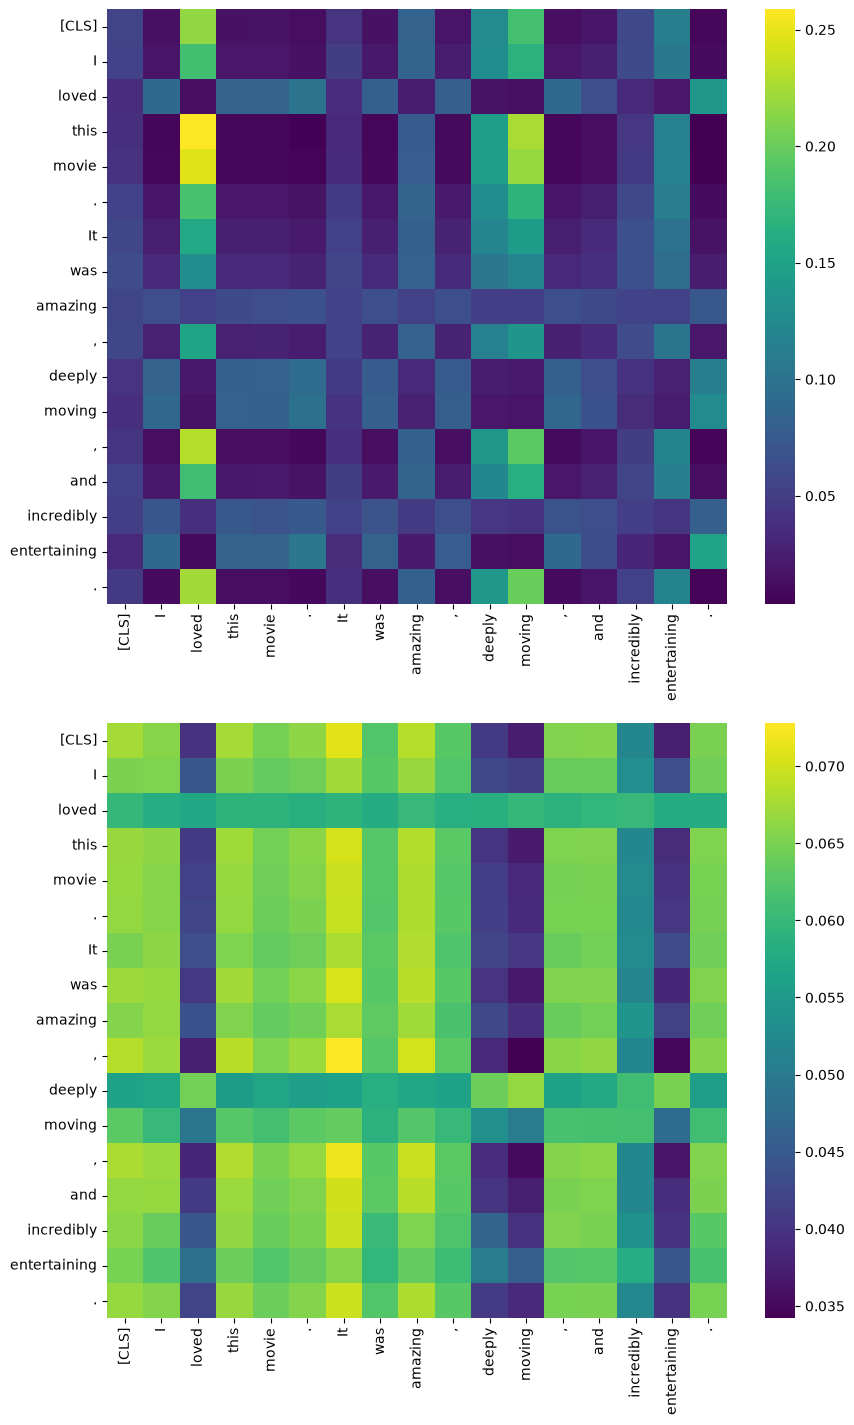

In [189]:
fig, ax = plt.subplots(2, 1, figsize=(10, 17))
plot_attention_scores(test_text, model_load_2, ax)

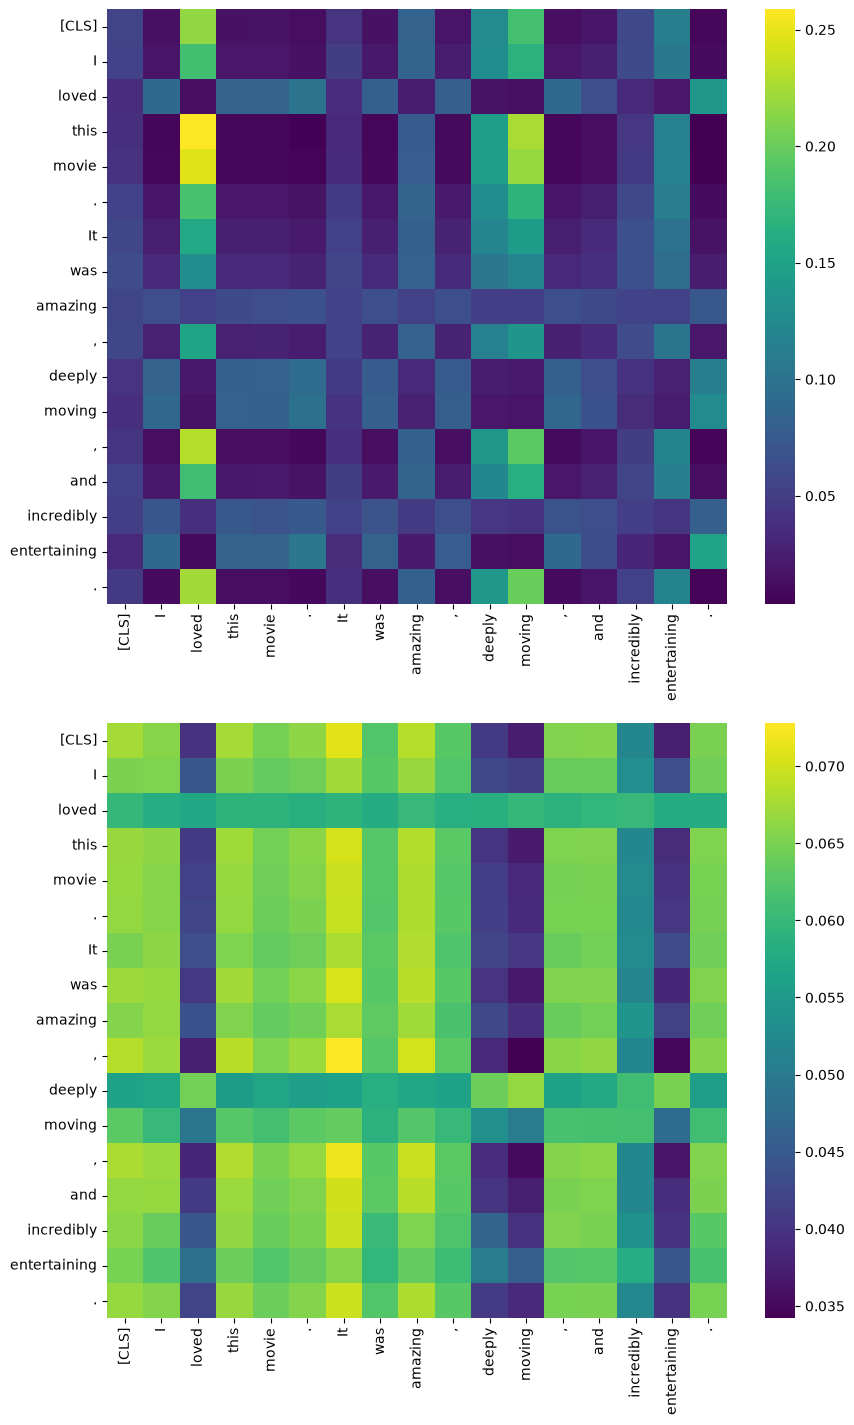

In [146]:
fig, ax = plt.subplots(2, 1, figsize=(10, 17))
plot_attention_scores(test_text, model_load_2, ax)

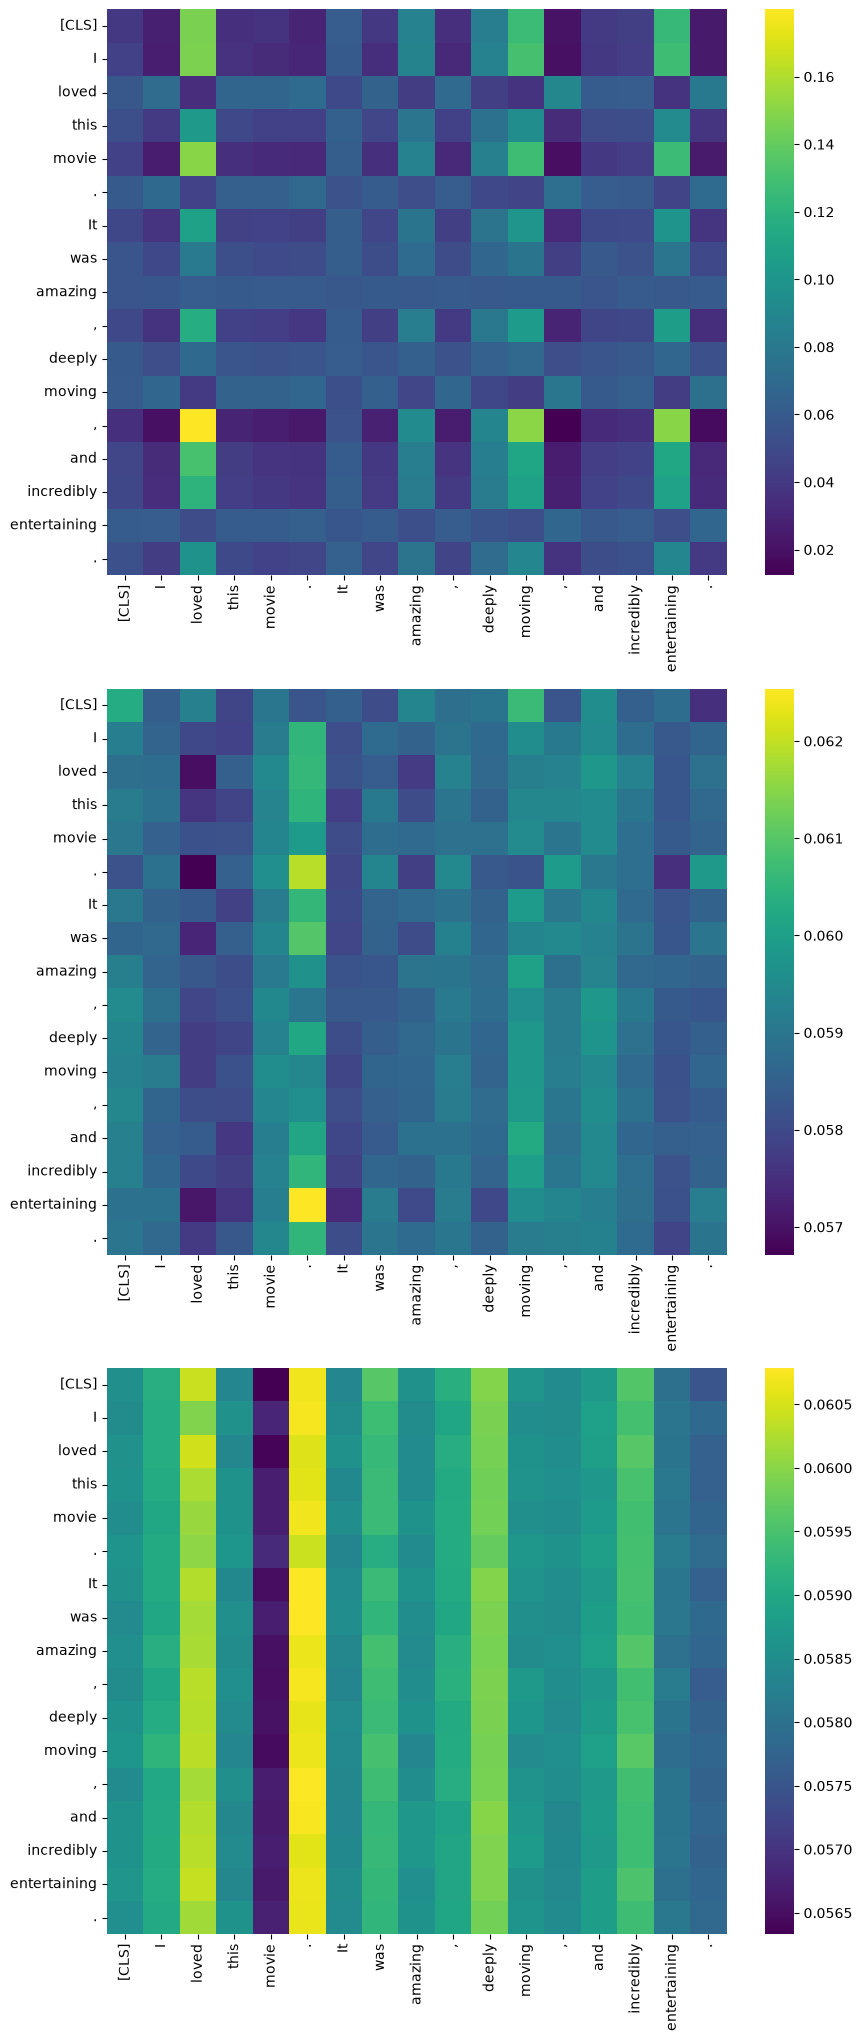

In [148]:
fig, ax = plt.subplots(3, 1, figsize=(10, 25))
plot_attention_scores(test_text, model_load_3, ax)

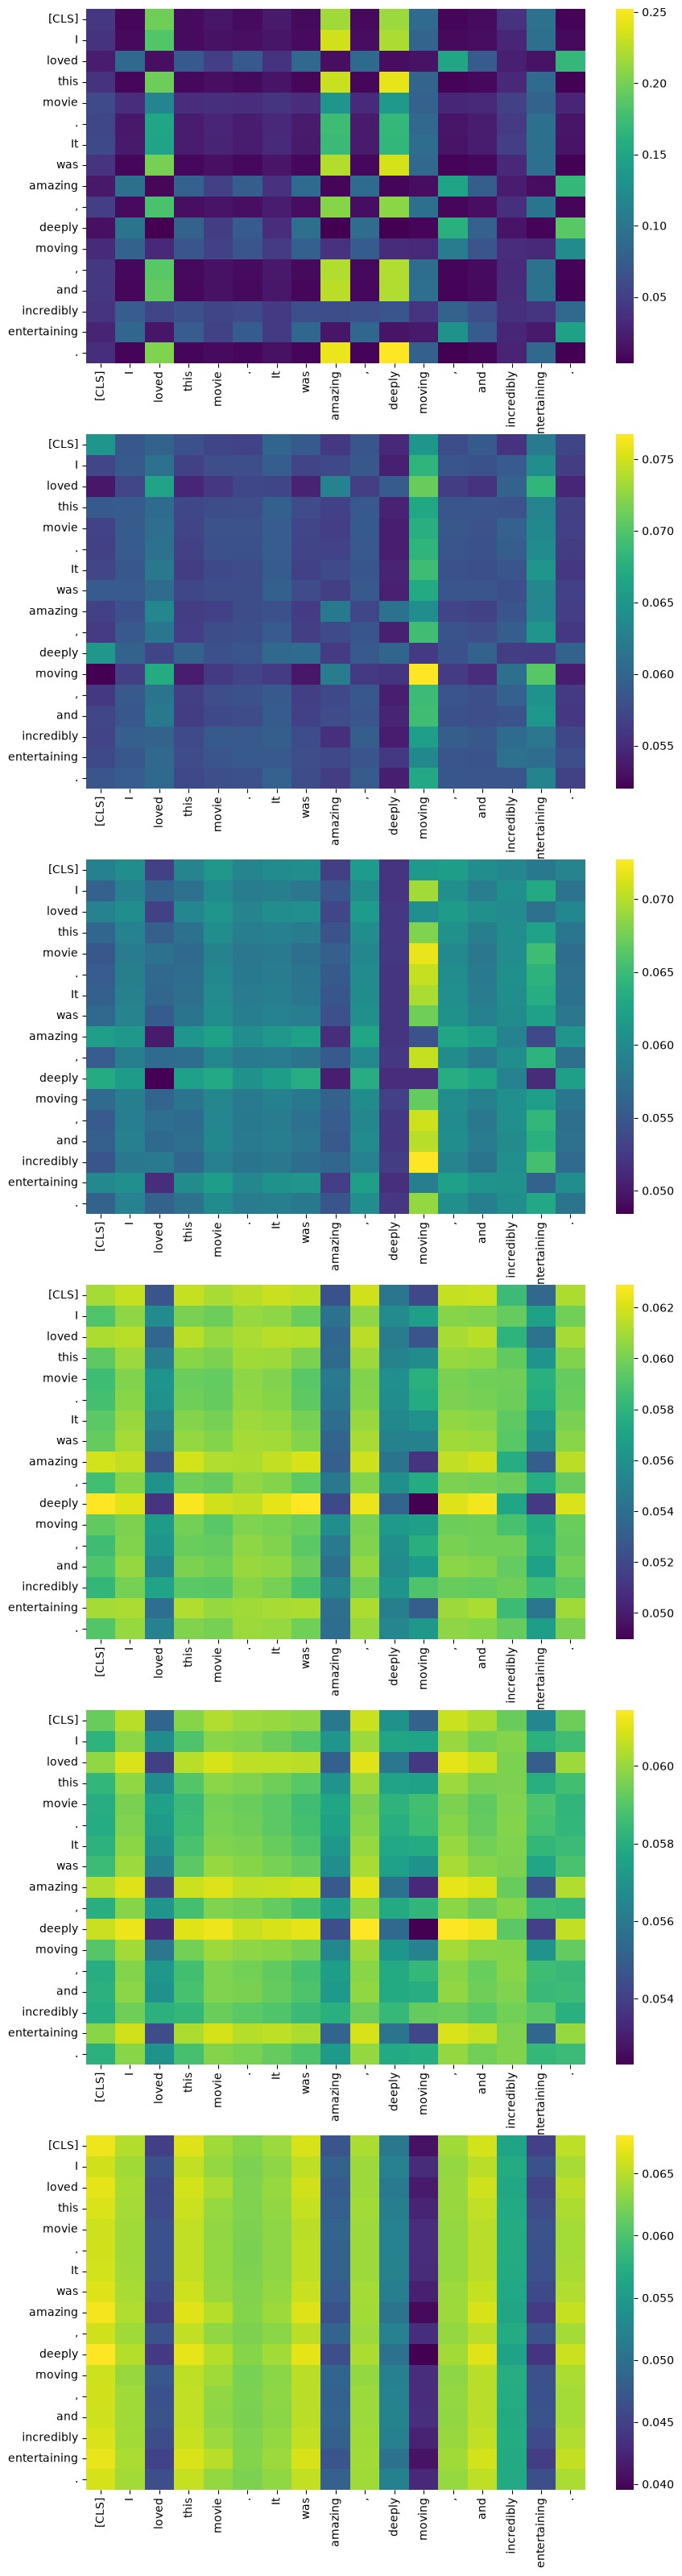

In [149]:
fig, ax = plt.subplots(6, 1, figsize=(10, 40))
plot_attention_scores(test_text, model_load_4, ax)

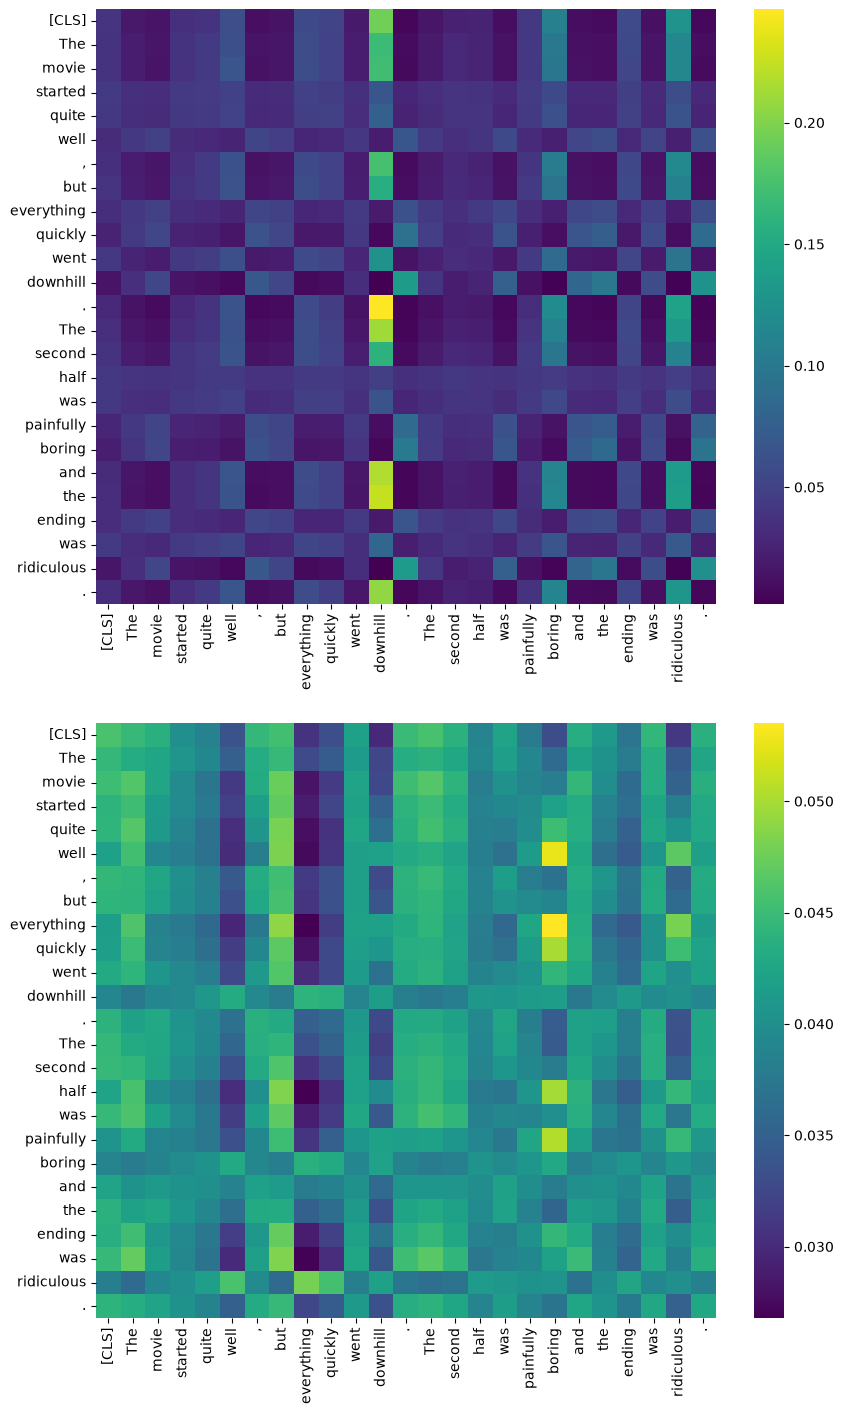

In [151]:
fig, ax = plt.subplots(2, 1, figsize=(10, 17))
plot_attention_scores(test_text_2, model_load_2, ax)